<a href="https://colab.research.google.com/github/nandah4/PCVK_Ganjil_26/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📘 MODUL 9 – Morfologi Citra
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi
**File:** `Week9.ipynb` (salinan disimpan ke GitHub lewat *File → Save a copy in GitHub*)

# 🔧 BAGIAN 0 – Persiapan

## 0.1 Menghubungkan Colab dengan GitHub dan Google Drive (Langkah 1)

Pekerjaan dimulai dari `https://colab.research.google.com/`. Pada dialog *Open notebook*
dipilih tab **GitHub**, lalu repository yang sudah dipakai pada praktikum minggu sebelumnya.
Supaya penamaan berkasnya sesuai ketentuan praktikum, notebook ini diberi nama
**`Week9.ipynb`** lewat `File > Save a copy in GitHub` (atau `File > Rename` bila pekerjaan
berlangsung langsung di repository tersebut).

Tahap berikutnya adalah menghubungkan folder Drive, persis seperti modul:

```python
from google.colab import drive
drive.mount('/content/drive')
```

> ℹ️ Drive perlu di-mount sekali di setiap sesi Colab baru. Bila Drive sudah ter-mount,
> sel ini hanya menampilkan pesan bahwa Drive sudah terpasang.

In [1]:
# Langkah 1 – mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0.2 Import library (Langkah 2)

| Library | Kegunaan |
|---|---|
| `cv2` (OpenCV) | membaca citra, threshold, dan operasi morfologi siap pakai |
| `numpy` | operasi matriks — dipakai untuk morfologi **manual** (tanpa library) |
| `matplotlib.pyplot` | menampilkan citra dan hasil setiap operasi |
| `os` | menyusun path berkas di folder Drive |
| `skimage` | `skeletonize`, `thin`, dan `threshold_triangle` (langkah 15–17) |

> 📌 OpenCV membaca citra berwarna dengan urutan kanal **BGR**, sedangkan `matplotlib`
> memakai **RGB**. Untuk citra keabuan yang mendominasi praktikum ini, perbedaan tersebut
> tidak berpengaruh.

In [2]:
# Langkah 2 – import library
import cv2
import numpy as np
from matplotlib import pyplot as plt

%matplotlib inline

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

OpenCV : 5.0.0
NumPy  : 2.1.3


## 0.3 Sumber berkas: Google Drive

Seluruh citra dibaca dari satu folder Drive berikut, yang sudah di-mount pada langkah 1:

```
/content/drive/MyDrive/Polinema/Semester 5/PCVK/Pertemuan 10
```

Path tersebut ditulis **sekali** di sel berikutnya, dan tiap langkah praktikum mengakses
berkas lewat fungsi **`path(nama_file)`**.

| Variabel | Keterangan |
|---|---|
| `GDRIVE_DIR` | folder Drive yang menyimpan kelima aset |
| `BERKAS_ASET` | daftar berkas yang mesti tersedia di folder tersebut |

> 📌 Bila folder dipindah atau diganti nama, penyesuaiannya hanya pada nilai `GDRIVE_DIR`.

In [3]:
# ==================== SUMBER RESOURCE: GOOGLE DRIVE ====================
GDRIVE_DIR  = "/content/drive/MyDrive/Polinema/Semester 5/PCVK/Pertemuan 10"
BERKAS_ASET = ["plat nomer.jpg", "kitten01.jpg", "lily.jpg", "j.png", "ktp.jpeg"]
# =======================================================================

import os

def path(nama_file):
    """Path lengkap sebuah resource di folder Drive."""
    return os.path.join(GDRIVE_DIR, nama_file)

print("Folder aset :", GDRIVE_DIR)

Folder aset : /content/drive/MyDrive/Polinema/Semester 5/PCVK/Pertemuan 10


In [4]:
# Cek ketersediaan seluruh resource di folder Drive
for nama in BERKAS_ASET:
    berkas = path(nama)
    print(("✅" if os.path.exists(berkas) else "❌"), nama)

✅ plat nomer.jpg
✅ kitten01.jpg
✅ lily.jpg
✅ j.png
✅ ktp.jpeg


## 0.4 Fungsi bantu tampilan

`tampilkan()` menyajikan beberapa citra berdampingan. Citra dua dimensi ditampilkan sebagai
grayscale, sedangkan citra tiga kanal (BGR) dikonversi ke RGB lebih dulu supaya warnanya tepat.

In [5]:
def tampilkan(daftar_citra, daftar_judul, figsize=(15, 4)):
    """Tampilkan beberapa citra berdampingan (grayscale maupun BGR)."""
    n = len(daftar_citra)
    plt.figure(figsize=figsize)
    for i, (citra, judul) in enumerate(zip(daftar_citra, daftar_judul), start=1):
        plt.subplot(1, n, i)
        if citra.dtype == bool:                      # hasil skeletonize/thin
            citra = citra.astype(np.uint8) * 255
        if citra.ndim == 3:
            plt.imshow(cv2.cvtColor(citra, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(citra, cmap="gray", vmin=0, vmax=255)
        plt.title(judul)
        plt.xticks([]), plt.yticks([])
    plt.show()

# 🧱 BAGIAN 1 – Operasi Dasar Morfologi

### Ringkasan teori
| Operasi | Cara kerja | Efek |
|---|---|---|
| **Erosi** ($A \ominus B$) | piksel pusat dipertahankan **hanya jika semua** piksel di bawah SE bernilai 1 | objek menyusut dan menipis, noise kecil hilang |
| **Dilasi** ($A \oplus B$) | piksel pusat menjadi 1 **jika minimal satu** piksel di bawah SE bernilai 1 | objek membesar dan menebal, bagian terputus tersambung |

Pada versi manual, tiap posisi pusat dihitung dengan:
- erosi → `np.min(temp * SE)`
- dilasi → `np.max(temp * SE)`

Nilai `np.min` dan `np.max` dipakai karena SE biner hanya "memilih" piksel yang berada di
posisi bernilai 1 pada SE.

## 1.1 Langkah 3 – Fungsi dilasi tanpa library (SED)

Fungsi `dilasi_citra(F, w)` menggeser *structuring element* berukuran `w × w` ke seluruh
citra, lalu mengambil nilai maksimum dari `temp * SED` di setiap posisi.

> ⚠️ **Catatan modul:** judul langkah ini menyebut SE *cross 3 × 3*, sedangkan kode modul
> memakai `np.ones((w, w))` dengan `w = 5` — sehingga SE yang benar-benar bekerja adalah
> **persegi 5 × 5**. Kode di bawah dipertahankan persis seperti modul; SE *cross* yang
> sesungguhnya baru muncul pada langkah 9.

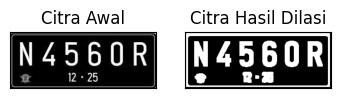

Ukuran SED : (5, 5) | piksel putih sebelum: 5150 | sesudah: 10906


In [6]:
#Dilasi tanpa library
def dilasi_citra(F, w):
    #size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print("Ukuran SED :", (w, w), "| piksel putih sebelum:", int((thresh > 0).sum()),
      "| sesudah:", int((imgD > 0).sum()))

## 1.2 Langkah 4 – Dilasi dengan library OpenCV

Operasi yang sama kini dikerjakan `cv2.dilate`. Kernelnya dibuat dengan
`np.ones((3, 3), np.uint16)` seperti pada modul.

[[1 1 1]
 [1 1 1]
 [1 1 1]]


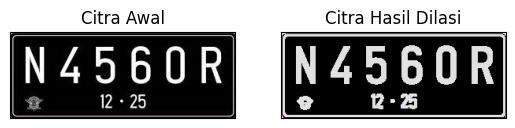

In [7]:
img = cv2.imread(path('plat nomer.jpg'))
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

## 1.3 Langkah 5 – Fungsi erosi tanpa library (SE persegi 5 × 5)

Erosi adalah kebalikan dilasi: nilai pusat diambil dari **minimum** `temp * SE`. Karena itu,
satu saja piksel bernilai 0 di dalam jendela SE membuat pusatnya ikut menjadi 0.

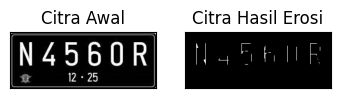

Ukuran SE : (5, 5) | piksel putih sebelum: 4765 | sesudah: 433


In [8]:
#Erosi Tanpa Library
def erosi_citra(F, k):
    #size image
    m, n = F.shape

    #Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print("Ukuran SE :", (k, k), "| piksel putih sebelum:", int((thresh1 > 0).sum()),
      "| sesudah:", int((imgE > 0).sum()))

## 1.4 Langkah 6 – Erosi dengan library OpenCV (SE persegi 5 × 5)

> 📝 Modul memberi judul "operasi dilasi" pada langkah ini, padahal kode di bawahnya memanggil
> `cv2.erode` dan judul gambarnya "Citra Hasil Erosi". Kode modul diikuti apa adanya, yaitu
> **erosi**.

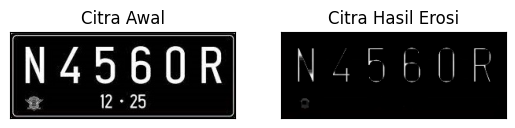

In [9]:
#EROSI LIBRARY
img = cv2.imread(path('plat nomer.jpg'))

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)
plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

# 🔗 BAGIAN 2 – Operasi Gabungan: Opening dan Closing

| Operasi | Urutan | Kegunaan |
|---|---|---|
| **Opening** | erosi → dilasi | membuang objek kecil dan noise di luar objek, memutus sambungan tipis; bersifat *idempotent* |
| **Closing** | dilasi → erosi | menutup lubang kecil di dalam objek, menyambung garis retak, merapikan tepi dalam |

Keduanya memakai SE yang sama pada kedua tahap.

## 2.1 Langkah 7 – Opening dengan SE persegi 3 × 3

### a) Tanpa library
Opening manual disusun sebagai `dilasi_citra(erosi_citra(citra, k), k)` memakai fungsi buatan
sendiri pada Bagian 1. Modul memakai `k = 7`.

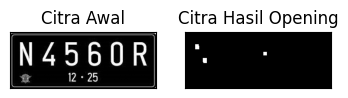

In [10]:
# Operasi Opening tanpa Library Morphology
img_o = cv2.imread(path('plat nomer.jpg'), 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

### b) Dengan library OpenCV

`cv2.morphologyEx(..., cv2.MORPH_OPEN, kernel)` menjalankan erosi lalu dilasi dalam satu
panggilan. Kernel yang dipakai modul: persegi **3 × 3**.

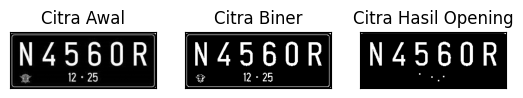

In [11]:
# Operasi Opening dengan Library Morphology
img = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

## 2.2 Langkah 8 – Closing dengan SE persegi 3 × 3

### a) Tanpa library
Closing manual disusun sebagai `erosi_citra(dilasi_citra(citra, k), k)` — urutannya
**kebalikan** dari opening.

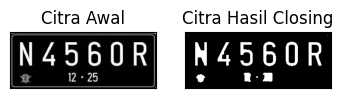

In [12]:
# Operasi closing tanpa library morphology
img_c = cv2.imread(path('plat nomer.jpg'), 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

### b) Dengan library OpenCV

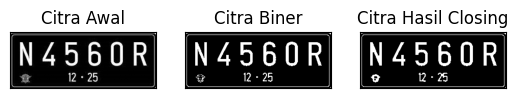

In [13]:
# Operasi closing dengan library morphology
img = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

# 🔷 BAGIAN 3 – Variasi Structuring Element

Bentuk SE sangat menentukan hasil. Bagian ini menguji empat bentuk yang paling sering
dipakai: **cross**, **circular (ellipse)**, **rectangle**, dan **line**.

| Bentuk | Dibuat dengan |
|---|---|
| Cross 3×3 / 5×5 | `np.array` manual |
| Circular 3×3 / 5×5 | `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))` |
| Rectangle 3×5 / 5×7 | `cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))` |
| Line vertikal 3 / 5 | `cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))` |

> 📌 Pada `cv2.getStructuringElement`, argumen ukuran mengikuti urutan **(lebar, tinggi)**,
> alih-alih (baris, kolom). Karena itu `(1, k)` menghasilkan garis **vertikal** setinggi `k`.

## 3.1 Langkah 9 – Dilasi SE **cross** 3 × 3 dan 5 × 5

SE cross dibuat manual dengan `np.array`, lalu `dilasi_citra` yang sama dipakai kembali.

SED = Cross 3


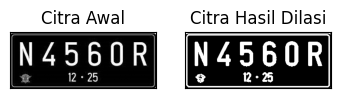

In [14]:
#Dilasi Cross SED 3x3
def dilasi_citra(F, w):
    #size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 5


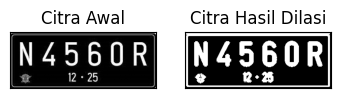

In [15]:
#Dilasi Cross SED 5x5
def dilasi_citra(F, w):
    #size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 3.2 Langkah 10 – Dilasi SE **circular** 3 × 3 dan 5 × 5

SE lingkaran dibuat dengan `cv2.MORPH_ELLIPSE`. Fungsi `dilasi_citra` di bawah tetap
**manual** — OpenCV di sini hanya bertugas membentuk SE, sementara proses dilasinya tetap
memakai perulangan buatan sendiri.

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


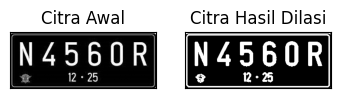

In [16]:
#Dilasi Circular SED
def dilasi_citra(F, w):
    #size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    #Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
print(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


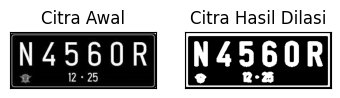

In [17]:
print('SED = Circle 5')
print(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
img_d = cv2.imread(path('plat nomer.jpg'), 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

## 3.3 Langkah 11 – Erosi SE **rectangle** 3 × 5 dan 5 × 7

Fungsi `erosi_citra(F, p, l)` menerima dua ukuran: `p` (lebar) dan `l` (tinggi). Urutan
`cv2.getStructuringElement` adalah **(lebar, tinggi)**, sehingga `(p, l)` menghasilkan SE
setinggi `l` dan selebar `p` — sepadan dengan jendela `(2*c1+1) × (2*c2+1)` di dalam loop.

SE = Rectangle 3x5
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]] 



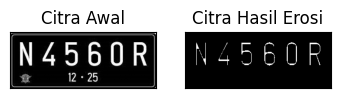

In [18]:
#Erosi Rectangle SE
def erosi_citra(F, p, l):
    #size image
    m, n = F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))  #SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

print('SE = Rectangle 3x5')
print(cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3)), '\n')
img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 5x7
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]] 



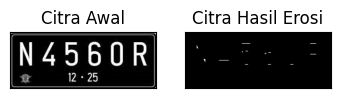

In [19]:
print('SE = Rectangle 5x7')
print(cv2.getStructuringElement(cv2.MORPH_RECT, (7, 5)), '\n')
img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

## 3.4 Langkah 12 – Erosi SE **line vertikal** 3 dan 5

`cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))` berarti **lebar 1, tinggi k** → garis
vertikal. Erosi dengan garis vertikal menghapus piksel yang tidak memiliki tetangga vertikal,
sehingga goresan horizontal tipis terkikis lebih dulu.

> 📝 Teks langkah menyebut berkas `j.png`, sedangkan kode dan tangkapan layar modul
> memakai `plat nomer.jpg`. Sel utama di bawah mengikuti kode modul, lalu ada **sel bonus**
> yang menjalankan fungsi yang sama pada `j.png` sesuai catatan langkah.

SE = Line Vertikal 3
[[1]
 [1]
 [1]] 



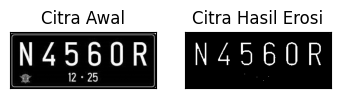

In [20]:
#Erosi Line Vertikal SE
def erosi_citra(F, k):
    #size image
    m, n = F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))  #SE line vertikal
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

print('SE = Line Vertikal 3')
print(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 3)), '\n')
img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 5
[[1]
 [1]
 [1]
 [1]
 [1]] 



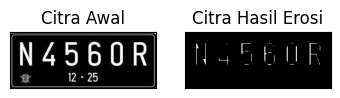

In [21]:
print('SE = Line Vertikal 5')
print(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, 5)), '\n')
img_e = cv2.imread(path('plat nomer.jpg'), 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

### Bonus – versi `j.png` (sesuai catatan langkah 12)

Huruf **J** pada `j.png` adalah objek yang tepat untuk menguji SE garis vertikal: goresan
horizontal pada kaki huruf J akan terkikis lebih dulu.

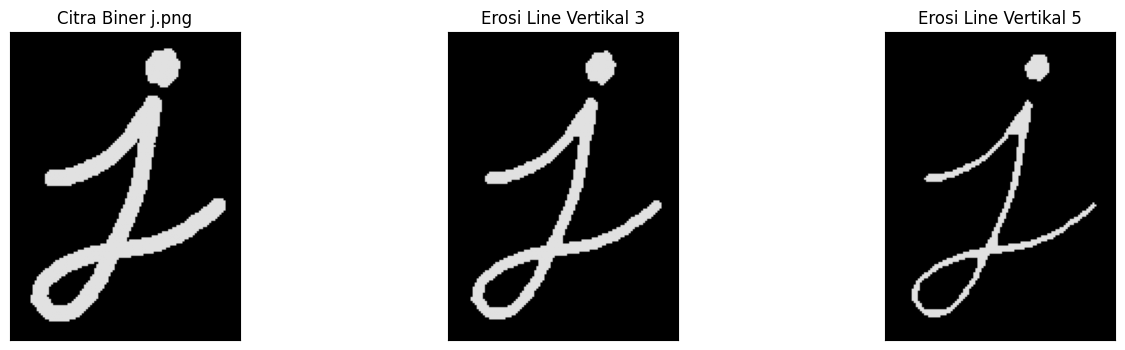

In [22]:
img_j = cv2.imread(path('j.png'), 0)
_, thresh_j = cv2.threshold(img_j, 127, 225, cv2.THRESH_BINARY)

hasil = [thresh_j]
judul = ['Citra Biner j.png']
for k in (3, 5):
    hasil.append(erosi_citra(thresh_j, k))
    judul.append(f'Erosi Line Vertikal {k}')

tampilkan(hasil, judul, figsize=(16, 4))

# 🎛️ BAGIAN 4 – Top-hat, Bottom-hat, Skeleton, Thickening

| Operasi | Rumus | Menonjolkan |
|---|---|---|
| **Top-hat / White-hat** | $That(f) = f - (f \circ b)$ | fitur **terang** yang lebih kecil dari SE |
| **Bottom-hat / Black-hat** | $Bhat(f) = (f \bullet b) - f$ | fitur **gelap** yang lebih kecil dari SE |
| **Skeleton** | hasil `skeletonize` / `thin` | kerangka objek setebal 1 piksel, topologi tetap terjaga |
| **Thickening** | kebalikan thinning | menebalkan objek menjadi kerangka tebal |

Top-hat dan bottom-hat diterapkan pada `kitten01.jpg`, sedangkan skeleton dan thickening
pada `lily.jpg`.

## 4.1 Langkah 13 – Top-hat

> 🔧 **Penyesuaian kecil:** kode modul memanggil `cv2.morphologyEx(input_image, ...)` padahal
> variabel yang dibuat bernama `img`, sehingga akan muncul `NameError`. Di sini dipakai `img`.
> Tangkapan layar modul juga memakai `kitten01.jpg`, sedangkan teks kodenya menulis
> `plat nomer.jpg`; di sini dipakai `kitten01.jpg` supaya hasilnya serupa dengan gambar modul.

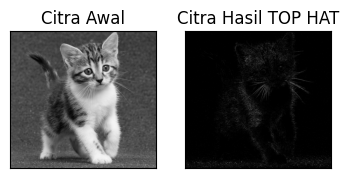

In [23]:
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread(path('kitten01.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

## 4.2 Langkah 14 – Bottom-hat (Black-hat)

Kernel yang dipakai modul untuk black-hat adalah persegi panjang **13 × 5**
(lebar 13, tinggi 5). Fitur gelap yang ukurannya lebih kecil dari kernel akan muncul terang.

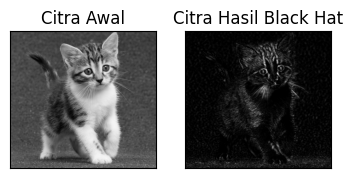

In [24]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread(path('kitten01.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)
#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

## 4.3 Langkah 15 – Skeleton

`skimage.morphology.skeletonize` menipiskan objek sampai setebal satu piksel dengan tetap
mempertahankan **konektivitas** dan **posisi** kerangka. Ambangnya ditentukan otomatis lewat
`filters.threshold_triangle`.

Citra dibinerkan dengan `img > threshold`, sehingga bagian **terang** (bunga) yang menjadi objek.

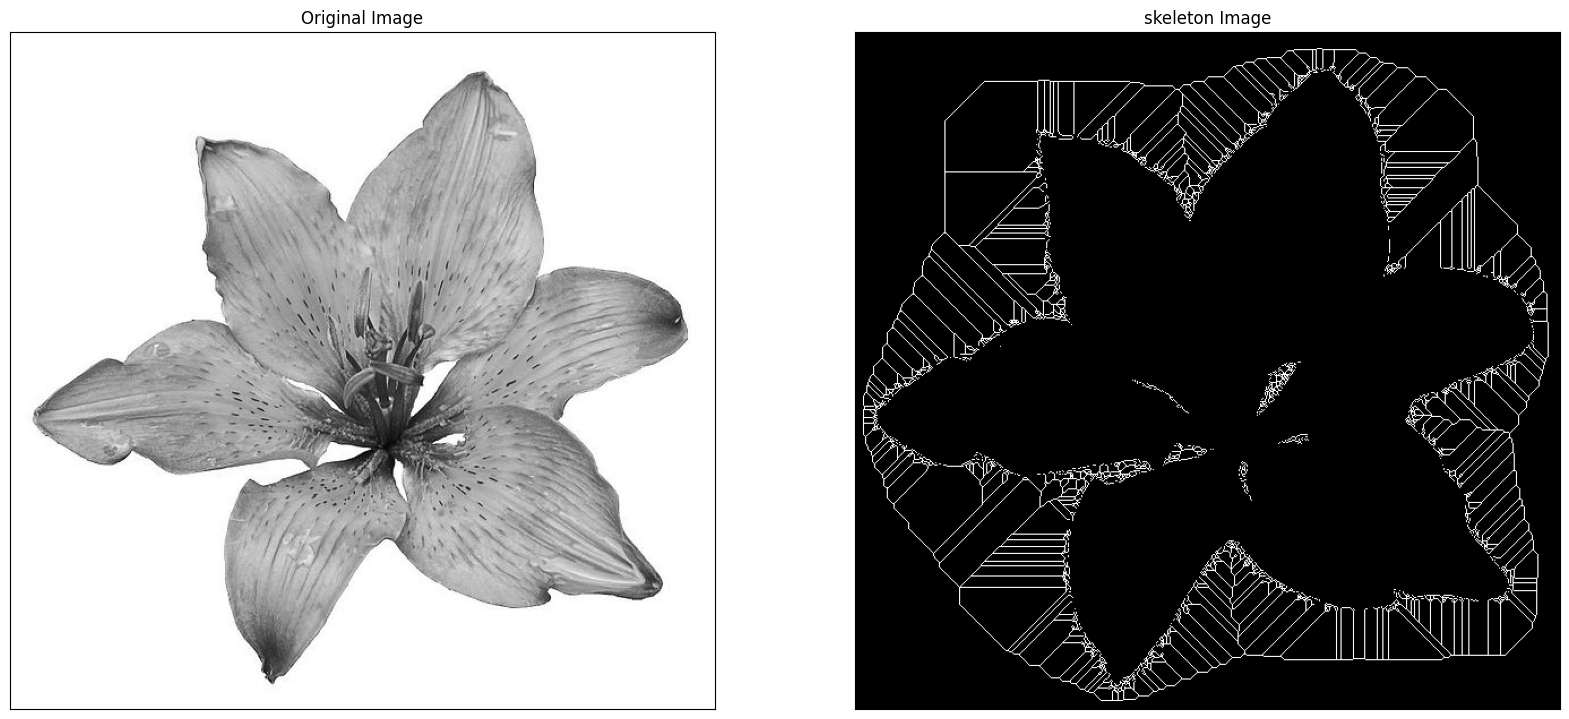

In [25]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread(path('lily.jpg'), 0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

## 4.4 Langkah 16 – Skeleton inverse

Kali ini bagian **gelap** (`img < threshold`) yang dijadikan objek, sehingga
kerangka mengikuti goresan gelap pada kelopak bunga. Hasilnya ditampilkan dengan colormap
`gray_r` supaya kerangka terlihat hitam di atas putih.

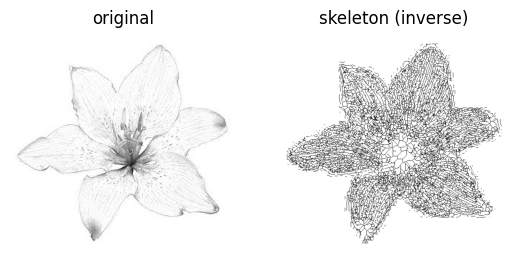

In [26]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread(path('lily.jpg'))[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

## 4.5 Langkah 17 – Thickening (thinning)

`morphology.thin` menghasilkan versi **tipis** dari objek biner (kebalikan dari *thickening*).
Pada modul, citra diubah ke float, dibinerkan dengan ambang `0.5`, lalu ditipiskan.
`morphology.skeletonize` juga dihitung sebagai pembanding.

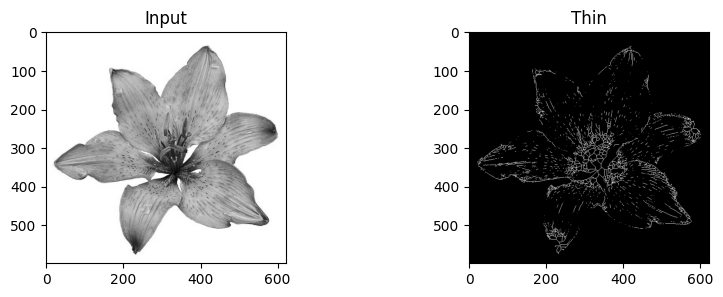

Jumlah piksel objek : 29755
Setelah skeletonize : 10305
Setelah thin        : 10280


In [27]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread(path('lily.jpg'))))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

print("Jumlah piksel objek :", int(image_binary.sum()))
print("Setelah skeletonize :", int(out_skeletonize.sum()))
print("Setelah thin        :", int(out_thin.sum()))

### 4.6 Pelengkap dari slide – morfologi grayscale, gradient, smoothing

*(bahan pengayaan dari PPT, di luar langkah jobsheet)*

Pada citra **grayscale**, konsep min/max tetap dipakai tetapi bekerja pada nilai intensitas:

$$(f \ominus b)(x,y) = \min_{(s,t)\in b} f(x+s,\ y+t)$$

$$(f \oplus b)(x,y) = \max_{(s,t)\in b} f(x+s,\ y+t)$$

- **Opening** pada grayscale mirip erosi, tetapi hasilnya lebih terang dan warna latarnya
  menyerupai citra asli.
- **Closing** pada grayscale hampir tidak mengubah tingkat terang, tetapi bagian gelapnya
  menjadi kabur tergantung ukuran dan bentuk SE.
- **Morphological gradient**: $g = (f \oplus b) - (f \ominus b)$ → menonjolkan tepi objek.
- **Morphological smoothing**: opening lalu closing dengan SE (disk) yang sama → menekan
  noise terang sekaligus noise gelap.

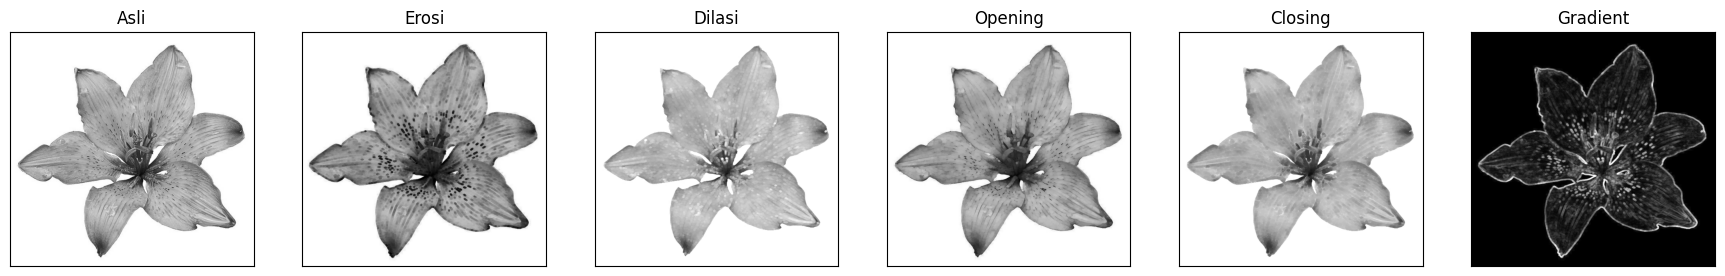

Rata-rata intensitas asli : 214.21
Setelah erosi             : 201.73
Setelah dilasi            : 224.33


In [28]:
# Morfologi grayscale (flat SE) pada lily.jpg
img_gray = cv2.imread(path('lily.jpg'), 0)
se_disk = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

g_erosi  = cv2.erode(img_gray, se_disk)
g_dilasi = cv2.dilate(img_gray, se_disk)
g_open   = cv2.morphologyEx(img_gray, cv2.MORPH_OPEN, se_disk)
g_close  = cv2.morphologyEx(img_gray, cv2.MORPH_CLOSE, se_disk)
g_grad   = cv2.morphologyEx(img_gray, cv2.MORPH_GRADIENT, se_disk)
g_smooth = cv2.morphologyEx(g_open, cv2.MORPH_CLOSE, se_disk)

tampilkan([img_gray, g_erosi, g_dilasi, g_open, g_close, g_grad],
          ["Asli", "Erosi", "Dilasi", "Opening", "Closing", "Gradient"],
          figsize=(22, 3.5))

print("Rata-rata intensitas asli :", round(float(img_gray.mean()), 2))
print("Setelah erosi             :", round(float(g_erosi.mean()), 2))
print("Setelah dilasi            :", round(float(g_dilasi.mean()), 2))

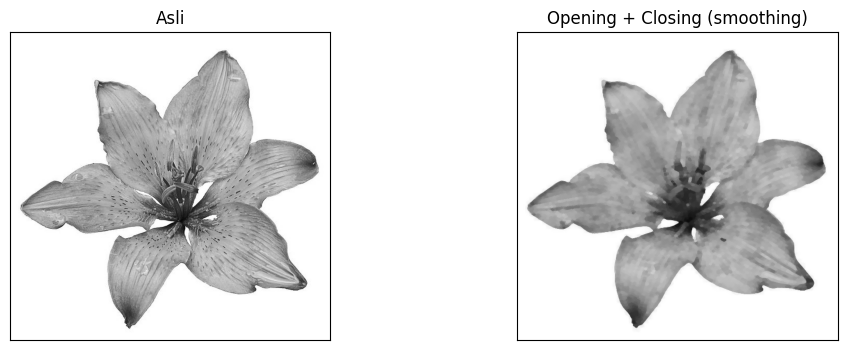

Rata-rata intensitas asli      : 214.21
Setelah morphological smoothing: 212.0


In [29]:
# Morphological smoothing = opening lalu closing
tampilkan([img_gray, g_smooth],
          ["Asli", "Opening + Closing (smoothing)"],
          figsize=(12, 4))

print("Rata-rata intensitas asli      :", round(float(img_gray.mean()), 2))
print("Setelah morphological smoothing:", round(float(g_smooth.mean()), 2))

# 🗂️ BAGIAN 5 – Tugas Praktikum: Morfologi pada Citra KTP

Tugas praktikum meminta penerapan morfologi pada **dataset KTP** (Modul 7) supaya citra KTP
**terbaca lebih baik**. Rangkaian yang dipakai:

| Tahap | Operasi | Tujuan |
|---|---|---|
| 1 | Grayscale | menyederhanakan citra ke satu kanal |
| 2 | Threshold tetap + `BINARY_INV` | tulisan (gelap) dijadikan objek putih; hasilnya masih **tipis dan terputus** |
| 3 | **Opening** | membuang bintik dan noise kecil |
| 4 | **Closing** | menyambung goresan huruf yang terputus agar terbaca |
| 5 | **Top-hat** dan **bottom-hat** | memisahkan tulisan dari latar yang tidak seragam |
| 6 | **Skeleton** | menipiskan huruf menjadi kerangka (pra-proses OCR) |
| 7 | Variasi ukuran kernel | melihat pengaruh besar SE terhadap keterbacaan |

Ukuran citra KTP : (458, 694)


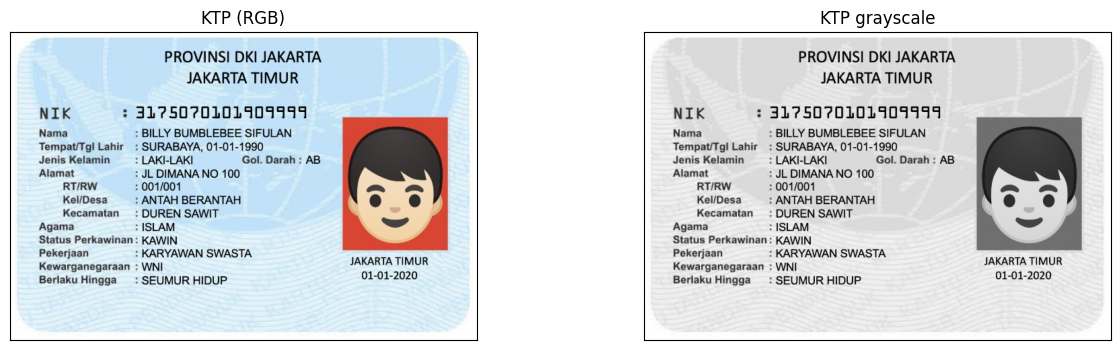

In [30]:
# Baca citra KTP
ktp_bgr = cv2.imread(path('ktp.jpeg'))
ktp = cv2.cvtColor(ktp_bgr, cv2.COLOR_BGR2GRAY)

print("Ukuran citra KTP :", ktp.shape)
tampilkan([ktp_bgr, ktp], ["KTP (RGB)", "KTP grayscale"], figsize=(15, 4))

### 5.1 Binerisasi: tulisan dijadikan objek putih

KTP punya latar terang dengan tulisan berwarna gelap. Supaya operasi morfologi bekerja pada
**tulisan**, hasil threshold dibalik memakai `THRESH_BINARY_INV` sehingga tulisan menjadi putih.

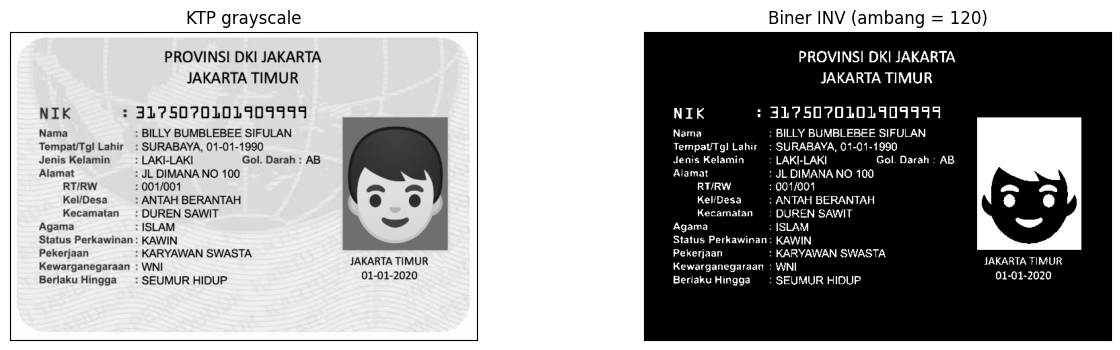

Piksel tulisan: 37640


In [31]:
# Binerisasi: tulisan (gelap) dijadikan putih
AMBANG = 120
_, ktp_bin = cv2.threshold(ktp, AMBANG, 255, cv2.THRESH_BINARY_INV)

tampilkan([ktp, ktp_bin],
          ["KTP grayscale", f"Biner INV (ambang = {AMBANG})"],
          figsize=(15, 4))

print("Piksel tulisan:", int((ktp_bin > 0).sum()))

### 5.2 Opening + Closing untuk memperbaiki tulisan

- **Opening 2×2** membuang bintik kecil sisa threshold.
- **Closing 2×2** menyambung goresan huruf yang terputus sehingga tulisan lebih tebal dan terbaca.

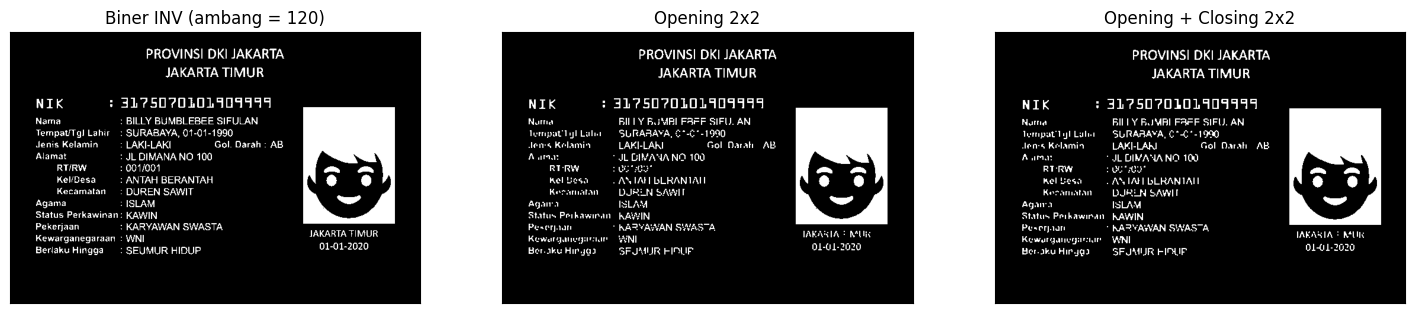

Piksel tulisan  biner  : 37640
Piksel tulisan  opening: 35780
Piksel tulisan  closing: 36193


In [32]:
# Opening 2x2 → menghilangkan noise/bintik kecil
k_open = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
ktp_open = cv2.morphologyEx(ktp_bin, cv2.MORPH_OPEN, k_open)

# Closing 2x2 → menyambung garis huruf yang terputus
k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
ktp_close = cv2.morphologyEx(ktp_open, cv2.MORPH_CLOSE, k_close)

tampilkan([ktp_bin, ktp_open, ktp_close],
          [f"Biner INV (ambang = {AMBANG})", "Opening 2x2", "Opening + Closing 2x2"],
          figsize=(18, 4))

print("Piksel tulisan  biner  :", int((ktp_bin > 0).sum()))
print("Piksel tulisan  opening:", int((ktp_open > 0).sum()))
print("Piksel tulisan  closing:", int((ktp_close > 0).sum()))

### 5.3 Perbandingan dengan ambang Otsu

Sebagai pembanding dipakai `THRESH_BINARY_INV + THRESH_OTSU`. Hasil morfologi dari ambang
tetap diharapkan setara atau lebih bersih daripada ambang otomatis.

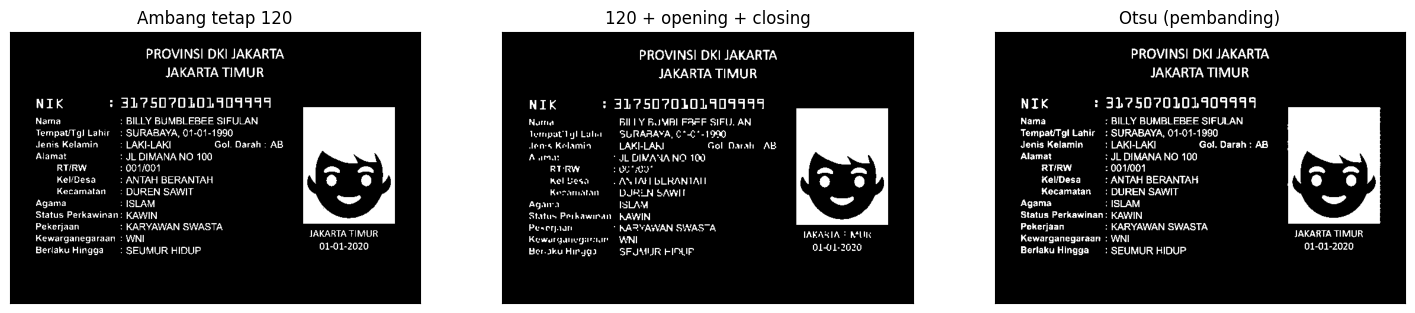

In [33]:
_, ktp_otsu = cv2.threshold(ktp, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

tampilkan([ktp_bin, ktp_close, ktp_otsu],
          [f"Ambang tetap {AMBANG}", f"{AMBANG} + opening + closing", "Otsu (pembanding)"],
          figsize=(18, 4))

### 5.4 Top-hat dan Bottom-hat pada KTP

- **Top-hat** menonjolkan fitur **terang** yang lebih kecil dari SE.
- **Bottom-hat** menonjolkan fitur **gelap** yang lebih kecil dari SE — pada KTP ini tulisan
  gelap justru tampil paling jelas.

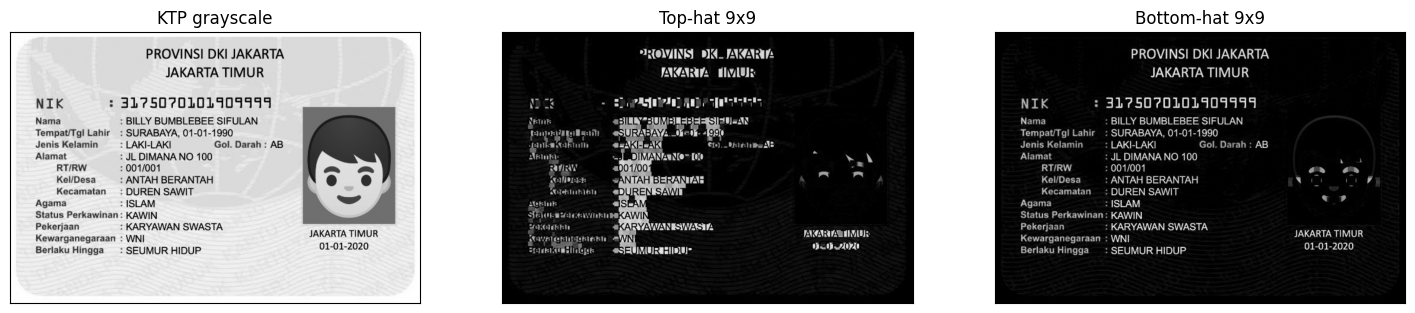

In [34]:
se9 = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
ktp_tophat = cv2.morphologyEx(ktp, cv2.MORPH_TOPHAT, se9)
ktp_blackhat = cv2.morphologyEx(ktp, cv2.MORPH_BLACKHAT, se9)

tampilkan([ktp, ktp_tophat, ktp_blackhat],
          ["KTP grayscale", "Top-hat 9x9", "Bottom-hat 9x9"],
          figsize=(18, 4))

### 5.5 Skeleton tulisan KTP

Kerangka (skeleton) berguna sebagai pra-proses OCR karena menyisakan satu piksel per goresan,
sementara arah dan bentuk hurufnya tetap dikenali.

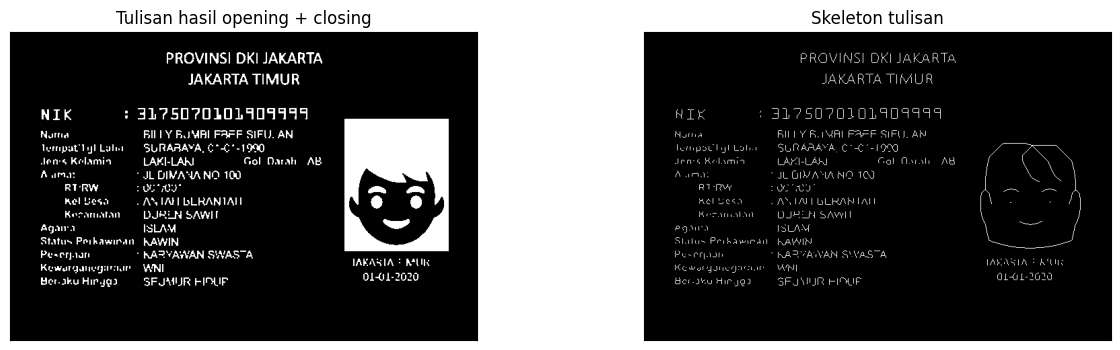

Piksel tulisan : 36193
Piksel skeleton: 6396


In [35]:
from skimage.morphology import skeletonize

ktp_skel = skeletonize(ktp_close > 0)

tampilkan([ktp_close, ktp_skel],
          ["Tulisan hasil opening + closing", "Skeleton tulisan"],
          figsize=(15, 4))

print("Piksel tulisan :", int((ktp_close > 0).sum()))
print("Piksel skeleton:", int(ktp_skel.sum()))

### 5.6 Pengaruh ukuran kernel pada Closing

Semakin besar SE, semakin agresif lubang dan retakan ditutup — tetapi huruf juga mulai
**menempel** satu sama lain sehingga keterbacaan bisa rusak.

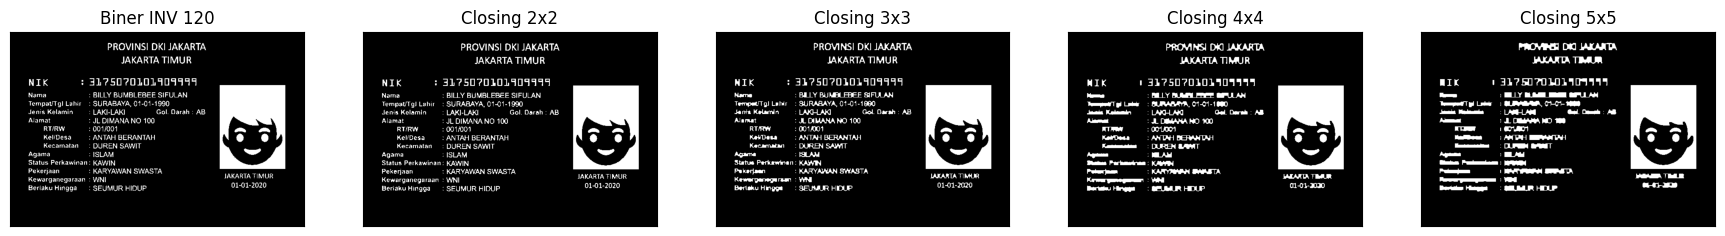

In [36]:
ukuran = [2, 3, 4, 5]
hasil = [ktp_bin]
judul = [f"Biner INV {AMBANG}"]
for u in ukuran:
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (u, u))
    hasil.append(cv2.morphologyEx(ktp_bin, cv2.MORPH_CLOSE, se))
    judul.append(f"Closing {u}x{u}")

tampilkan(hasil, judul, figsize=(22, 4))

### 5.7 Perbesaran area NIK

Supaya penilaian keterbacaan lebih adil, area NIK diperbesar untuk membandingkan hasil biner
mentah dengan hasil **opening + closing**.

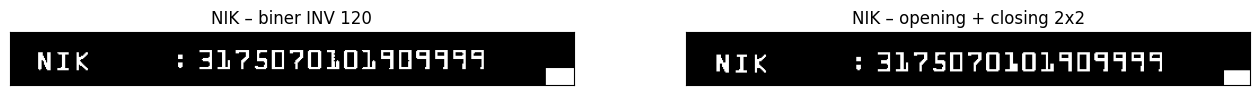

In [37]:
y0, y1, x0, x1 = 95, 142, 20, 520   # area NIK
tampilkan([ktp_bin[y0:y1, x0:x1], ktp_close[y0:y1, x0:x1]],
          [f"NIK – biner INV {AMBANG}", "NIK – opening + closing 2x2"],
          figsize=(16, 3))